# Customer Churn Prediction — Complete End-to-End Data Science Project

**Objective:** Build a reproducible churn prediction workflow from business framing to model deployment.

## Business framing

The business wants to identify customers at risk of leaving so that a retention team can prioritize outreach. This is a binary classification problem. We will evaluate ranking performance and threshold-dependent precision/recall, then select a decision threshold using validation data.


## 1. Imports and reproducibility

In [4]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, RocCurveDisplay, PrecisionRecallDisplay
)
import joblib

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

Project root: d:\Data_Science_Projects\customer-churn-prediction
Dataset path: d:\Data_Science_Projects\customer-churn-prediction\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv


## 2. Load and validate data

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Place the Telco churn CSV at: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
required_columns = {
    "customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().sort_values(ascending=False).head(15))
display(df["Churn"].value_counts(dropna=False))
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

Duplicate rows: 0


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

## 3. Data cleaning and exploratory data analysis

In [7]:
# TotalCharges is sometimes imported as text because some rows contain blanks.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Inspect missing values after numeric conversion.
display(df.isna().sum().sort_values(ascending=False).head(15))

TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
dtype: int64

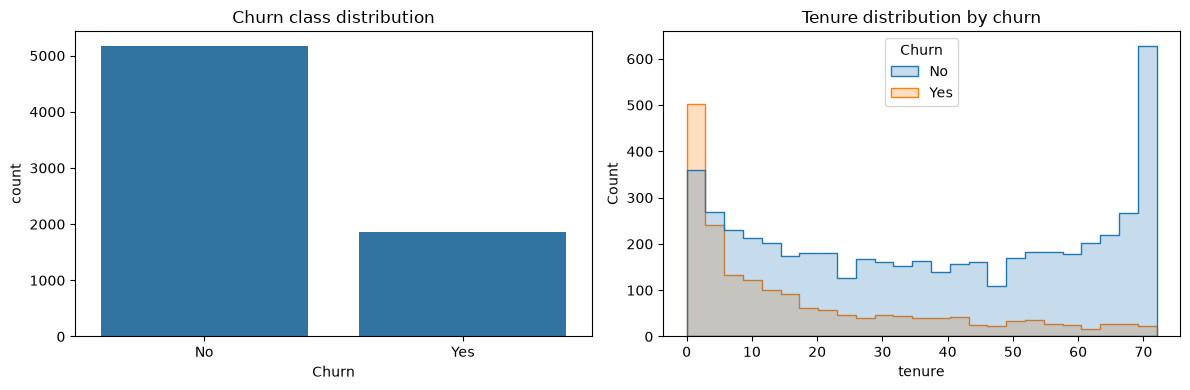

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Churn class distribution")

sns.histplot(data=df, x="tenure", hue="Churn", bins=25, element="step", ax=axes[1])
axes[1].set_title("Tenure distribution by churn")
plt.tight_layout()
plt.show()

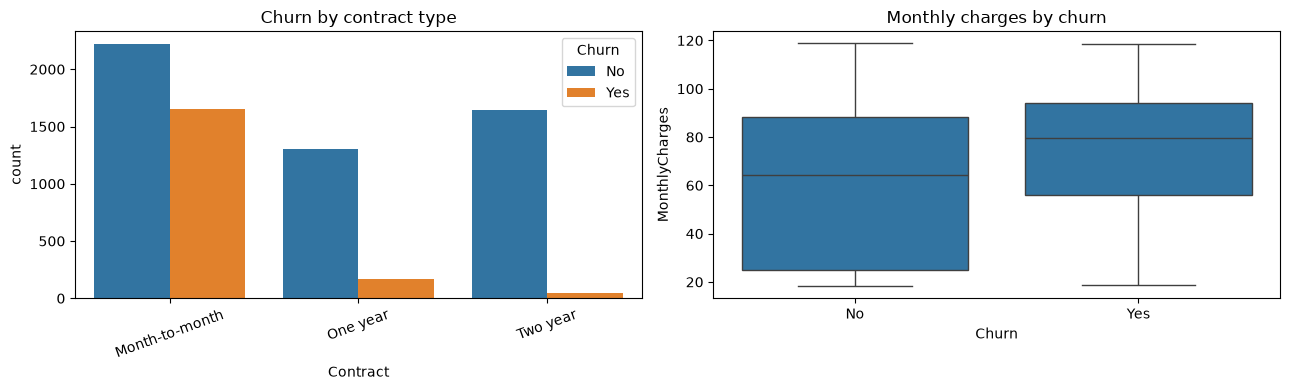

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_title("Churn by contract type")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

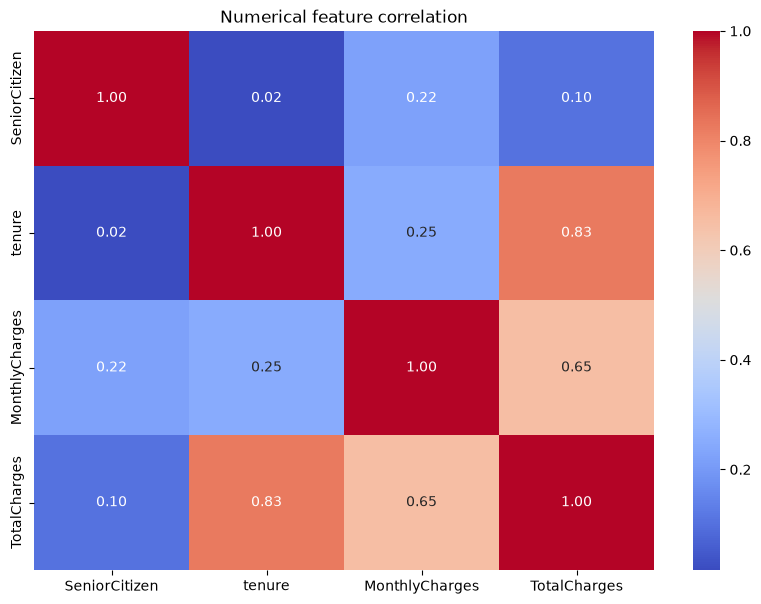

In [10]:
numeric_eda = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_eda.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical feature correlation")
plt.show()

### EDA interpretation prompts

Write your own observations before modeling:
1. What is the churn prevalence?
2. How does churn vary across contract types?
3. How does tenure differ between churn groups?
4. Which columns have missing values, and why?
5. Which columns are identifiers or unavailable at prediction time?

Correlation and group differences are descriptive; they do not establish causality.

## 4. Define target and split the data

In [11]:
# Customer ID is an identifier, not a model feature.
model_df = df.drop(columns=["customerID"]).copy()
y = model_df.pop("Churn").map({"No": 0, "Yes": 1})

if y.isna().any():
    raise ValueError("Churn contains unexpected or missing values.")

X = model_df
print("Features:", X.shape)
print("Target distribution:")
display(y.value_counts(normalize=True))

Features: (7043, 19)
Target distribution:


Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

In [12]:
# 60% train, 20% validation, 20% final test.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_val
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (4225, 19)
Validation: (1409, 19)
Test: (1409, 19)


## 5. Feature engineering and preprocessing

In [13]:
class ChurnFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["tenure_years"] = X["tenure"] / 12.0
        X["avg_charge_per_tenure_month"] = np.where(
            X["tenure"] > 0,
            X["TotalCharges"] / X["tenure"],
            np.nan
        )
        return X


numeric_features = [
    "SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges",
    "tenure_years", "avg_charge_per_tenure_month"
]
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

def build_pipeline(estimator):
    return Pipeline([
        ("feature_engineering", ChurnFeatureEngineer()),
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

## 6. Model comparison with stratified cross-validation

In [14]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

comparison = []
pipelines = {}

for name, estimator in models.items():
    pipe = build_pipeline(estimator)
    pipelines[name] = pipe
    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    comparison.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring}
    })

comparison_df = pd.DataFrame(comparison).sort_values("roc_auc", ascending=False)
display(comparison_df)

,Model,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.522137,0.804643,0.633106,0.847780,0.665019
2,Gradient Boosting,0.660729,0.521885,0.582463,0.845029,0.665662
1,Random Forest,0.578178,0.653040,0.613085,0.833978,0.631628


## 7. Hyperparameter tuning

In [15]:
# Demonstration: tune Logistic Regression. Expand the search for other candidates
# only after defining a fair comparison strategy.
logistic_pipe = pipelines["Logistic Regression"]

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": ["balanced", None]
}

search = GridSearchCV(
    logistic_pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best mean CV ROC-AUC:", search.best_score_)
best_model = search.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'model__C': 100, 'model__class_weight': None}
Best mean CV ROC-AUC: 0.8483405893571392


## 8. Select a decision threshold using validation data

In [16]:
validation_probabilities = best_model.predict_proba(X_val)[:, 1]

threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    predictions = (validation_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)

# Example objective only: maximize validation F1.
best_threshold = float(
    threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"]
)
print("Validation-selected threshold:", best_threshold)

,threshold,precision,recall,f1
0,0.20,0.467552,0.847594,0.602662
1,0.25,0.502538,0.794118,0.615544
2,0.30,0.531429,0.745989,0.620690
3,0.35,0.566239,0.708556,0.629454
4,0.40,0.597015,0.641711,0.618557
5,0.45,0.622159,0.585561,0.603306
6,0.50,0.659016,0.537433,0.592047
7,0.55,0.696154,0.483957,0.570978
8,0.60,0.716418,0.385027,0.500870
9,0.65,0.741259,0.283422,0.410058


Validation-selected threshold: 0.35


Threshold choice is a business decision. F1 is used here for demonstration.
For a real retention operation, consider campaign capacity, contact cost,
customer lifetime value, false-negative cost and probability calibration.
Do not use the final test set to choose this threshold.

## 9. Final fit and one-time held-out test evaluation

In [17]:
# Refit the selected hyperparameters on train + validation.
# Keep the threshold selected using validation predictions.
final_model = search.best_estimator_
final_model.fit(X_train_val, y_train_val)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

print(classification_report(
    y_test, test_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))
print("PR-AUC:", average_precision_score(y_test, test_probabilities))

              precision    recall  f1-score   support

    No Churn       0.88      0.79      0.83      1035
       Churn       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC: 0.8407760469141543
PR-AUC: 0.6261907794825563


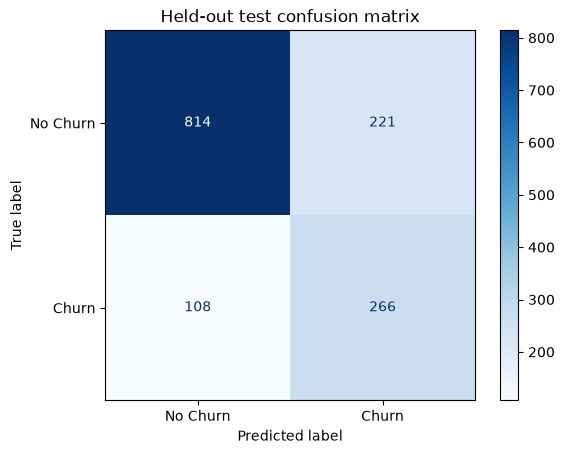

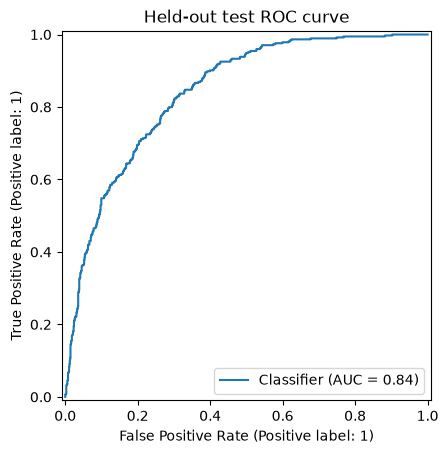

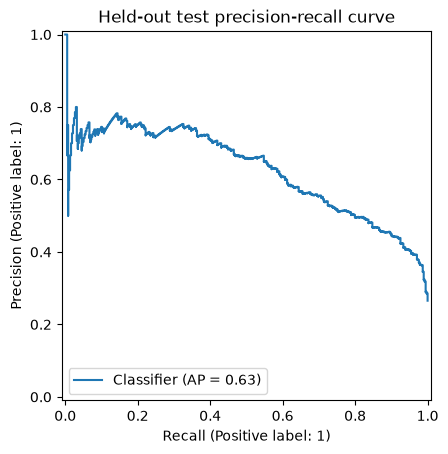

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("Held-out test confusion matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Held-out test ROC curve")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_probabilities)
plt.title("Held-out test precision-recall curve")
plt.show()

## 10. SHAP interpretation

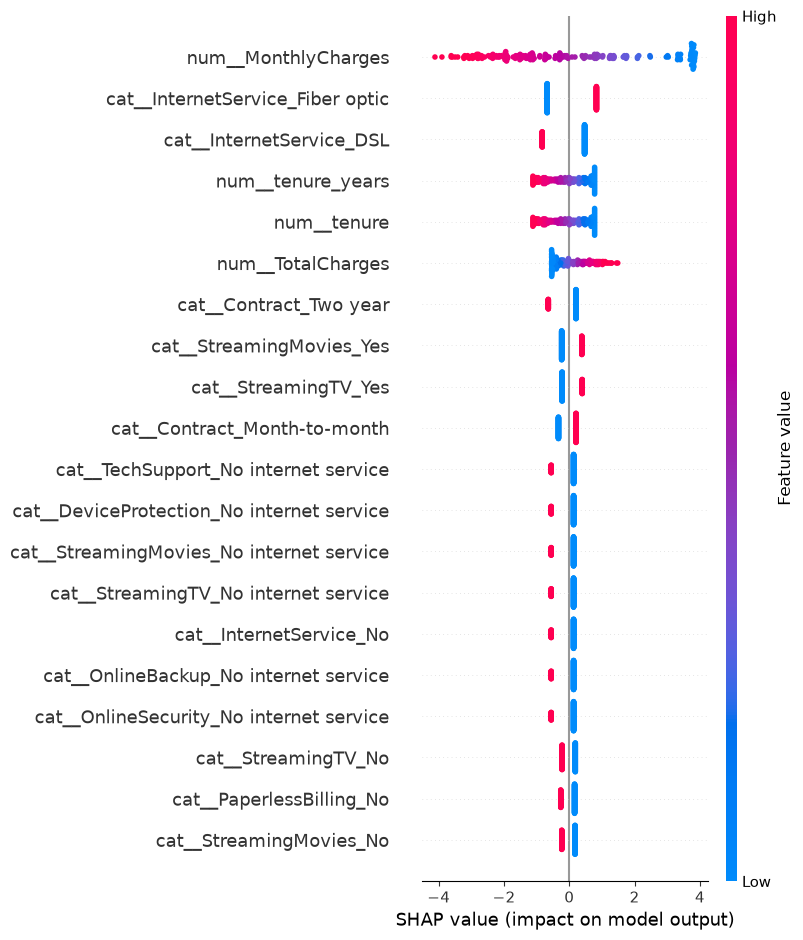

In [19]:
# SHAP is optional. If installation/import fails, continue with permutation
# importance or Logistic Regression coefficients.
try:
    import shap

    fitted_feature_engineer = final_model.named_steps["feature_engineering"]
    fitted_preprocessor = final_model.named_steps["preprocessor"]
    fitted_classifier = final_model.named_steps["model"]

    X_train_engineered = fitted_feature_engineer.transform(X_train_val)
    X_train_transformed = fitted_preprocessor.transform(X_train_engineered)
    X_train_dense = (
        X_train_transformed.toarray()
        if hasattr(X_train_transformed, "toarray")
        else np.asarray(X_train_transformed)
    )

    feature_names = fitted_preprocessor.get_feature_names_out()
    background = X_train_dense[: min(100, len(X_train_dense))]
    explain_data = X_train_dense[: min(200, len(X_train_dense))]

    explainer = shap.LinearExplainer(fitted_classifier, background)
    shap_values = explainer(explain_data)

    shap.summary_plot(
        shap_values.values,
        explain_data,
        feature_names=feature_names
    )
except ImportError:
    print("SHAP is not installed. Install it with: pip install shap")

SHAP values for this Logistic Regression explainer are on the model's raw
output (log-odds) scale. They explain model behavior, not causation.

## 11. Save pipeline, metadata and evaluation report

In [20]:
metadata = {
    "project": "Customer Churn Prediction",
    "model": "Logistic Regression",
    "threshold": best_threshold,
    "target": "Churn",
    "positive_class": "Yes",
    "random_state": RANDOM_STATE
}

evaluation = {
    "best_params": search.best_params_,
    "best_cv_roc_auc": float(search.best_score_),
    "threshold": best_threshold,
    "test_roc_auc": float(roc_auc_score(y_test, test_probabilities)),
    "test_pr_auc": float(average_precision_score(y_test, test_probabilities)),
    "test_precision": float(precision_score(y_test, test_predictions, zero_division=0)),
    "test_recall": float(recall_score(y_test, test_predictions, zero_division=0)),
    "test_f1": float(f1_score(y_test, test_predictions, zero_division=0)),
    "confusion_matrix": confusion_matrix(y_test, test_predictions).tolist()
}

joblib.dump(final_model, MODEL_DIR / "churn_pipeline.joblib")
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
with open(REPORT_DIR / "model_evaluation.json", "w", encoding="utf-8") as f:
    json.dump(evaluation, f, indent=2)

print("Saved:", MODEL_DIR / "churn_pipeline.joblib")
print("Saved:", MODEL_DIR / "metadata.json")
print("Saved:", REPORT_DIR / "model_evaluation.json")

Saved: d:\Data_Science_Projects\customer-churn-prediction\models\churn_pipeline.joblib
Saved: d:\Data_Science_Projects\customer-churn-prediction\models\metadata.json
Saved: d:\Data_Science_Projects\customer-churn-prediction\reports\model_evaluation.json


## 12. Reload and run a sample prediction

In [21]:
loaded_model = joblib.load(MODEL_DIR / "churn_pipeline.joblib")
sample_customer = X_test.iloc[[0]]
sample_probability = float(loaded_model.predict_proba(sample_customer)[0, 1])
sample_prediction = int(sample_probability >= best_threshold)

print("Probability:", round(sample_probability, 4))
print("Prediction:", "Churn" if sample_prediction else "No churn")

Probability: 0.0488
Prediction: No churn


## 13. Monitoring starter

count    1409.000000
mean        0.267965
std         0.246220
min         0.001465
25%         0.040455
50%         0.192671
75%         0.476392
max         0.853307
Name: churn_probability, dtype: float64

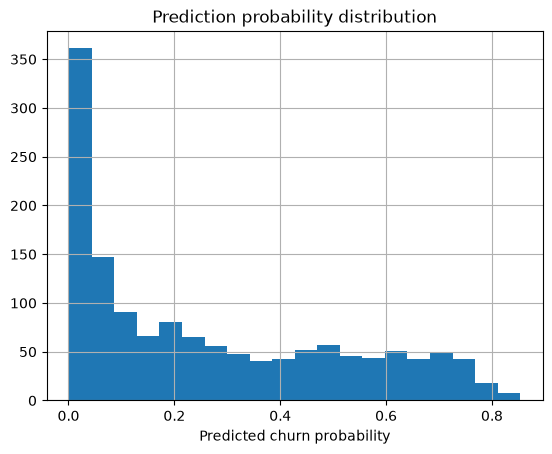

In [22]:
monitoring = pd.DataFrame({
    "churn_probability": test_probabilities,
    "actual_churn": y_test.to_numpy(),
    "predicted_churn": test_predictions
})
display(monitoring["churn_probability"].describe())

monitoring["churn_probability"].hist(bins=20)
plt.title("Prediction probability distribution")
plt.xlabel("Predicted churn probability")
plt.show()

In production, log timestamp, model version, prediction, threshold and approved
input diagnostics. Join predictions to actual churn outcomes when labels mature.
Monitor feature drift, prediction drift, model metrics, latency, errors and
business outcomes. Drift alone is not a reason to automatically retrain.